# MI Part 1: Data Audit, EDA and Baseline Regression
**Provider Network Access and Cost Planner** · David Satizabal · CAI4510C Machine Intelligence

**Question:** how much will each member cost the health plan over the **next three months**?

The AI side places members with doctors. This part predicts cost so the planner can spread the expensive members out and place the sickest first. It's a **supervised regression** problem: we learn from past members whose next-quarter cost we already know, and predict a dollar amount.

**Data:** 1,500 synthetic members (the first 600 are the AI Part 1 members) followed monthly from January 2025 to September 2026. Each member's distance to the nearest in-network PCP comes from **A\* search in AI Part 1**. On June 1, 2026 a large provider group (Pinecrest) leaves the network, which we'll need to catch later. All data is seeded (seed 42) and contains no real people.

**To run in Colab:** run the first cell. If the files are missing, it clones the class repo, or asks you to upload `MI_Part1_EDA_Regression.zip`.

In [1]:
# Find the project folder. If it's missing: clone the class repo, and if that fails, ask for the zip
import sys, os, zipfile, subprocess
from pathlib import Path

FOLDER = "MI_Part1_EDA_Regression"
CANDIDATES = [Path.cwd(), Path.cwd() / FOLDER, Path("/content") / FOLDER,
              Path("/content/Artificial-Intelligence-Class") / FOLDER]
find = lambda: next((p for p in CANDIDATES if (p / "src" / "run_mi_part1.py").exists()), None)
PROJECT = find()

if PROJECT is None and Path("/content").exists():
    subprocess.run(["git", "clone", "-q", "-b", "finalProject", "https://github.com/DASatizabal/Artificial-Intelligence-Class",
                    "/content/Artificial-Intelligence-Class"])
    PROJECT = find()

if PROJECT is None:
    try:
        from google.colab import files
        print(f"Project folder not found. Upload {FOLDER}.zip")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        PROJECT = find()
    except ImportError:
        raise FileNotFoundError(f"Put this notebook inside the {FOLDER} folder, or run it in Colab.")

os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("Project folder:", PROJECT.name)

Project folder: MI_Part1_EDA_Regression


This cell finds the project files. In Colab it clones the class repo (finalProject branch), and if that fails it asks for a zip upload, so nothing crashes.

In [2]:
import pandas as pd, json
import gen_claims
gen_claims.main()        # rebuilds data/member_months.csv from seed 42
raw = pd.read_csv("data/member_months.csv", dtype={"zip": str})
display(raw.head())

31,563 rows | 1500 members | 2025-01 to 2026-09
miles to PCP: mean 2.70 before, 3.10 after Pinecrest leaves; 170 members farther


,member_id,month,age,sex,zip,county,plan_type,chronic_conditions,miles_to_pcp,saw_pcp_last_3m,er_visits_6m,admits_12m,cost_month,cost_prior_3m,cost_prior_12m,cost_next_3m
0,M0001,2025-01,70,M,33156,Miami-Dade,Medicare Advantage,6,3.0,1,1,0,464.48,1561.35,7928.74,1072.34
1,M0002,2025-01,60,M,33030,Miami-Dade,Medicaid,0,3.0,0,2,0,0.00,1819.90,1819.90,128.00
2,M0003,2025-01,71,M,33014,Miami-Dade,Medicare Advantage,2,2.0,1,1,0,55.01,1283.86,6463.90,630.75
3,M0004,2025-01,43,M,33015,Miami-Dade,Medicaid,2,2.0,1,0,0,314.09,584.16,1943.71,347.30
4,M0005,2025-01,54,M,33176,Miami-Dade,Marketplace,3,4.0,0,0,0,70.81,896.97,7000.18,1403.83


Each row is **one member in one month**. Everything in the row is known by the end of that month: age, chronic conditions, miles to PCP, whether they saw their PCP in the last 3 months, ER visits and hospital admissions recently, and what they cost this month, last quarter, and last year. The last column, `cost_next_3m`, is the answer we're trying to predict.

The data was built with two assumptions of my own, written in the generator: each extra mile to the PCP raises ER visits by 10%, and skipping checkups raises ER use. That's the "access drives cost" idea from the proposal.

In [3]:
import run_mi_part1
run_mi_part1.main()
display(pd.read_csv("outputs/audit.csv"))

                Check                                       Finding                                       Action
                Shape                      31,563 rows x 16 columns                                         None
       Duplicate rows                                            63                 Removed (double-loaded rows)
     Members / months 1,500 members, 21 months (2025-01 to 2026-09)               Split by month, never randomly
    Missing plan_type                                    472 (1.5%)      Fill with 'Unknown' inside the pipeline
 Other missing values                                             0                                         None
  Negative cost_month                          40 rows, min $-3,800       Kept: claim reversals are real refunds
            Age range                                      18 to 95                                        Valid
         Miles to PCP                                       0 to 11               Valid (CMS lim

,Check,Finding,Action
0,Shape,"31,563 rows x 16 columns",NaN
1,Duplicate rows,63,Removed (double-loaded rows)
2,Members / months,"1,500 members, 21 months (2025-01 to 2026-09)","Split by month, never randomly"
3,Missing plan_type,472 (1.5%),Fill with 'Unknown' inside the pipeline
4,Other missing values,0,NaN
5,Negative cost_month,"40 rows, min $-3,800",Kept: claim reversals are real refunds
6,Age range,18 to 95,Valid
7,Miles to PCP,0 to 11,Valid (CMS limit for PCP is 5)
8,Target cost_next_3m,"median $472, mean $1,967, max $218,118",Very skewed: also model log(cost)
9,Top 10% share of cost,64.8%,The few drive most spend (sets up MI Part 2)


**The audit (look before you cook).** Every finding has an action:
- **63 duplicate rows** were loaded twice, so they're removed.
- **472 rows (1.5%) are missing plan type**, so they get an "Unknown" label inside the pipeline instead of being dropped.
- **40 negative monthly costs** are claim reversals (refunds), which are real, so they're kept.
- **The target is extremely lopsided.** The middle member costs \$435 a quarter, but the average is \$1,736, because **the top 10% of rows account for 66.1% of all cost**. That's the reason MI Part 2 builds a high-cost flag. About 10.7% of rows cost \$0 next quarter.

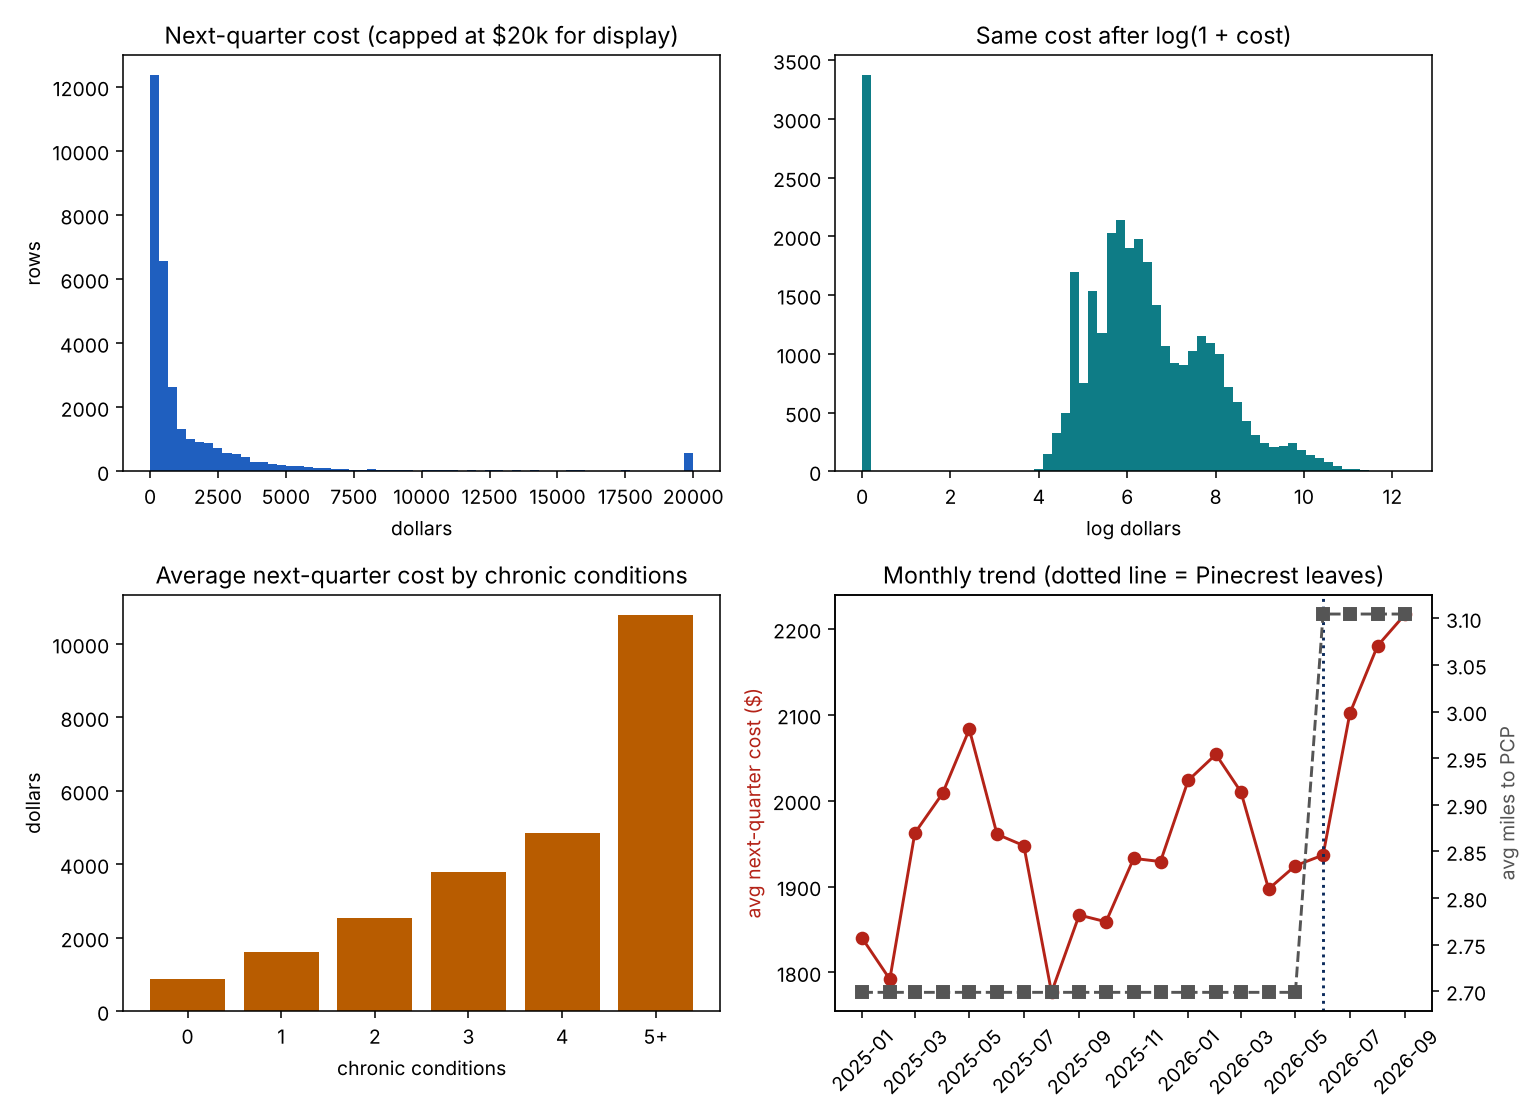

In [4]:
from IPython.display import Image
Image("outputs/eda_overview.png")

Four charts:
- **Top left:** most members cost a little and a few cost a lot (a long right tail).
- **Top right:** taking the log squeezes that tail into a hump, which linear models handle better. The spike at 0 is members with no claims.
- **Bottom left:** cost climbs with chronic conditions, from about \$900 with none to over \$10,000 with 5 or more.
- **Bottom right:** average miles to a PCP jumps on June 1, 2026 when Pinecrest leaves. Cost rises in the months after. A model trained before that date will be working on a changed world, which is the drift we'll monitor in the capstone.

,miles_to_pcp,rows,saw_pcp,er_6m,next_q_cost
0,0-2,15731,0.693,0.543,1839.499
1,3-5,13276,0.550,0.766,1984.590
2,6-8,1690,0.405,1.038,2663.031
3,9+,803,0.138,1.164,2704.196


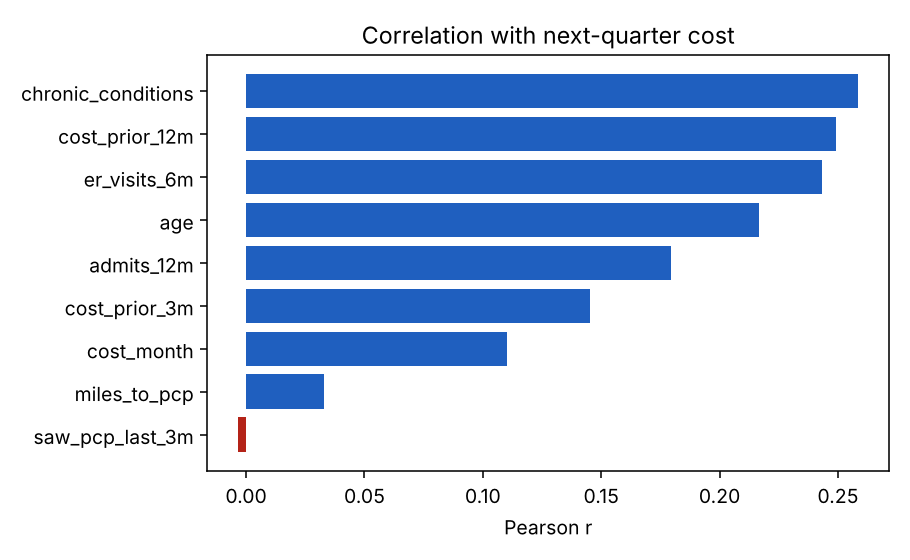

In [5]:
m = json.load(open("outputs/metrics.json"))
display(pd.DataFrame(m["access_bands"]))
Image("outputs/correlations.png")

**The link to AI Part 1.** Members 9 or more miles from a PCP see their doctor far less often (13.8% had a visit in the last 3 months, vs 69.3% for members within 2 miles). They also go to the ER about twice as often (1.16 vs 0.54 visits in 6 months), and cost about \$2,700 next quarter vs \$1,840.

The plain correlation between miles and cost is only 0.03, though. Distance matters for a small group, and a correlation averages it away across everyone. That's a good reminder to look at groups, not just one number. Chronic conditions (0.26) and last year's cost (0.25) are the strongest single signals.

In [6]:
scores = pd.DataFrame(m["scores"]); display(scores)
print("Split:", m["split"], "| train rows:", m["train_rows"], "| test rows:", m["test_rows"])

,model,MAE,RMSE,R2
0,Mean of training rows,2446.353,7758.000,-0.000
1,Last quarter repeats,2609.799,8837.355,-0.298
2,Linear regression,2167.622,7425.549,0.084
3,"Log model, typical member (median)",1834.406,8099.361,-0.090


Split: {'train': ['2025-01', '2025-09'], 'gap': ['2025-10', '2025-12'], 'test': ['2026-01', '2026-02']} | train rows: 13500 | test rows: 3000


**How we tested (no peeking).** We train on January to September 2025 and test on January to February 2026. October to December 2025 is skipped on purpose. A row's answer covers the *next* three months, so a September row's answer runs through December. If training rows went past September, their answers would overlap the test period.

**The scorecard:**

| Model | MAE (average miss) | What it tells us |
|---|---|---|
| Guess the training average for everyone | \$2,446 | The bar to beat |
| "Next quarter = last quarter" | \$2,610 | Worse than the average, because one bad quarter often isn't repeated |
| **Linear regression** | **\$2,168** | Beats both, R² = 0.084 |
| Log model, typical member | \$1,834 | Best average miss, but its RMSE is worse (\$8,099 vs \$7,426) because it underestimates the huge bills |

The R² is low, and that's normal for predicting next quarter's health care cost from claims alone. A lot of cost comes from events nobody can see coming. The point of a baseline is the bar it sets, and every model in later Parts has to beat \$2,168.

,dollars per 1 standard deviation (or vs. reference group)
cost_prior_12m,851.9
chronic_conditions,631.3
plan_type_Medicare Advantage,431.7
age,346.0
plan_type_Medicaid,-269.3
admits_12m,-246.9
plan_type_Unknown,-230.7
er_visits_6m,223.7
saw_pcp_last_3m,-221.4
cost_month,74.0


Negative predictions from the linear model: 126


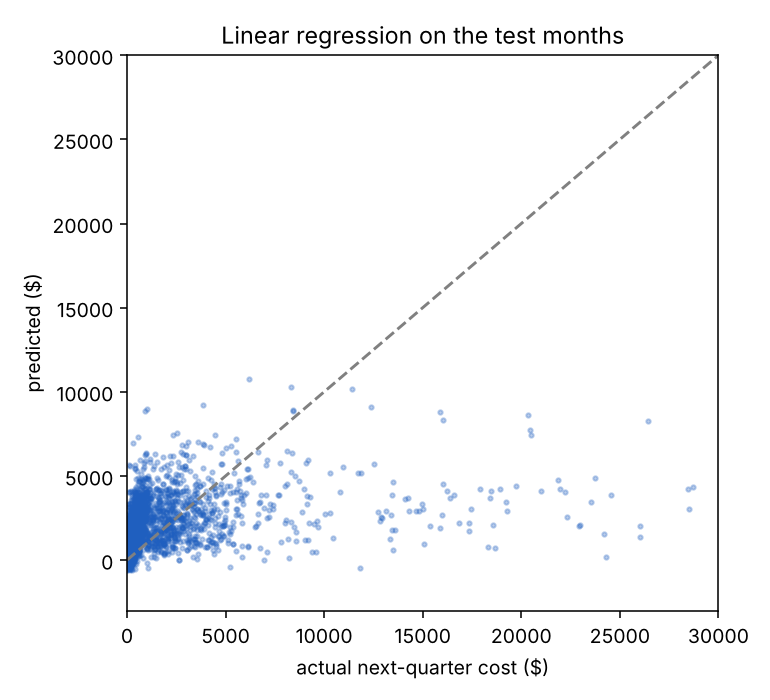

In [7]:
coef = pd.Series(m["linear_coefficients_per_1sd"]).head(10)
display(coef.to_frame("dollars per 1 standard deviation (or vs. reference group)"))
print("Negative predictions from the linear model:", m["negative_predictions_linear"])
Image("outputs/pred_vs_actual.png")

**What the linear model learned:** last year's cost and chronic conditions push predictions up the most (about \$850 and \$630 per standard deviation), followed by Medicare Advantage and age. Not seeing a PCP recently adds cost. Two honest weaknesses show up in the picture:
- The model **predicts below \$0 for 126 rows**, which a straight line can do.
- It **can't reach the very large bills**. All the dots on the right sit far below the diagonal.

Both problems point to the next steps: a yes/no high-cost flag (MI Part 2) and models that can bend (trees and neural nets).

**Summary.** The data is clean after removing 63 duplicates and labeling 472 missing plan types. Cost is extremely lopsided, with the top 10% driving 66% of spend. Distance to a PCP matters for the far-away group. Linear regression beats both simple baselines, with an average miss of \$2,168.